<!-- Presenter notes (0:00–0:12): Open with the distinction: the engine turns difficult employee-plan evidence into a reviewable research record. It does not issue a trade instruction. -->
# Employee Flow Event Engine

## From filing evidence to **review-gated** event-study inputs

The engine converts employee stock purchase plan (ESPP) references into structured research evidence with provenance, confidence, and explicit review controls—**not automatic trade instructions**.

> This 2–3 minute walkthrough uses the repository’s deterministic Phase 3 fixture workflow. All inputs are local; `TST` / TestCo is illustrative fixture data.

<!-- Presenter notes (0:12–0:30): Explain that filing language can describe a schedule, a plan rule, or an actual completed purchase. The workflow makes those distinctions inspectable before research windows are built. -->
## 1. The research problem

Employee-flow references are difficult to use directly: filing text may be incomplete, recurring, administrative, or unrelated to an observed purchase. This repository makes the path auditable:

**screen filings → extract bounded evidence → classify and deduplicate candidates → apply review decisions → generate validated event windows**

The review gate is intentional. A plausible date is not treated as a confirmed event merely because it appeared near ESPP language.

In [1]:
from pathlib import Path
import contextlib
import io
import logging
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
start_dir = Path.cwd().resolve()
ROOT = next((path for path in (start_dir, *start_dir.parents) if (path / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.chdir(ROOT)

SOURCE_CONFIG = ROOT / "config" / "phase3_reviewed_fixture.yaml"
DEMO_OUTPUT = ROOT / "artifacts" / "employee_flow_event_engine_demo"
DEMO_CACHE = ROOT / "artifacts" / "employee_flow_event_engine_demo_cache"
print("Ready: local, deterministic Phase 3 reviewed-workflow fixture")

Ready: local, deterministic Phase 3 reviewed-workflow fixture


<!-- Presenter notes (0:30–0:47): Show that the demo starts with a deliberately small filing fixture. Call out the metadata and concise source excerpt; this is the evidence layer, not a hidden model feature. -->
## 2. Small, inspectable input

The canonical deterministic Phase 3 fixture contains four short filing records for one illustrative issuer. The production workflow accepts the same filing-document contract from local fixtures or an SEC cache/live acquisition path.

In [2]:
from src.data.sec_parser import load_filing_documents_from_fixtures

documents = load_filing_documents_from_fixtures(
    ROOT / "fixtures" / "sec_filings" / "phase3_reviewed_fixture", ticker="TST"
)
input_view = pd.DataFrame(
    [{
        "Filing": document.filing_type,
        "Filed": document.filing_date.isoformat(),
        "Source ID": document.source_id,
        "Evidence excerpt": document.text.strip(),
    } for document in documents]
)
display(
    input_view.style
    .hide(axis="index")
    .set_properties(subset=["Evidence excerpt"], **{"width": "520px", "white-space": "normal"})
    .set_table_styles([{"selector": "th", "props": [("background-color", "#102a43"), ("color", "white")]}])
)

Filing,Filed,Source ID,Evidence excerpt
10-K,2024-02-15,tst_fixture_001,"The Employee Stock Purchase Plan purchase date is March 29, 2024 for the spring offering period."
DEF 14A,2024-04-15,tst_fixture_002,"The Employee Stock Purchase Plan purchase date is June 28, 2024 for the summer offering period."
10-K,2024-08-01,tst_fixture_003,"The Employee Stock Purchase Plan purchase date is September 30, 2024 for the autumn offering period."
DEF 14A,2024-10-15,tst_fixture_004,"The Employee Stock Purchase Plan purchase date is December 31, 2024 for the winter offering period."


<!-- Presenter notes (0:47–1:05): This is the real batch pipeline, not notebook reimplementation. Explain that the runtime config preserves the tracked fixture inputs and only redirects generated artifacts to a demo-specific ignored directory. -->
## 3. Run the real Phase 3 pipeline

The cell below calls the repository’s batch entry point. It uses the tracked reviewed-fixture configuration unchanged except for demo-specific artifact and cache directories, so recording does not alter the repository’s example artifacts.

✓ Pipeline completed — 1 illustrative issuer, 4 candidates, local fixtures only


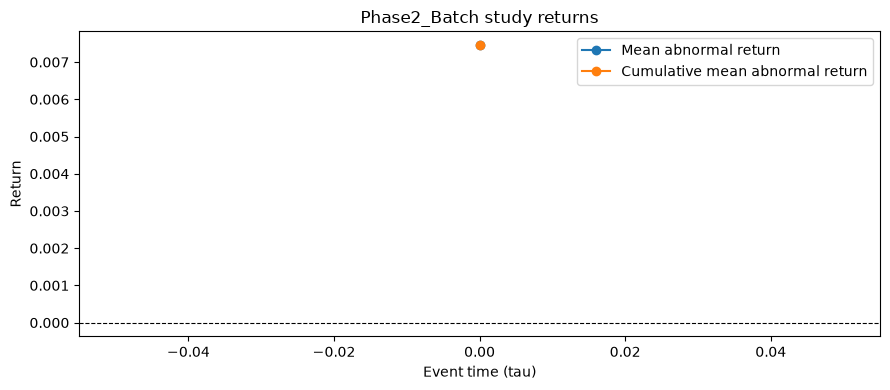

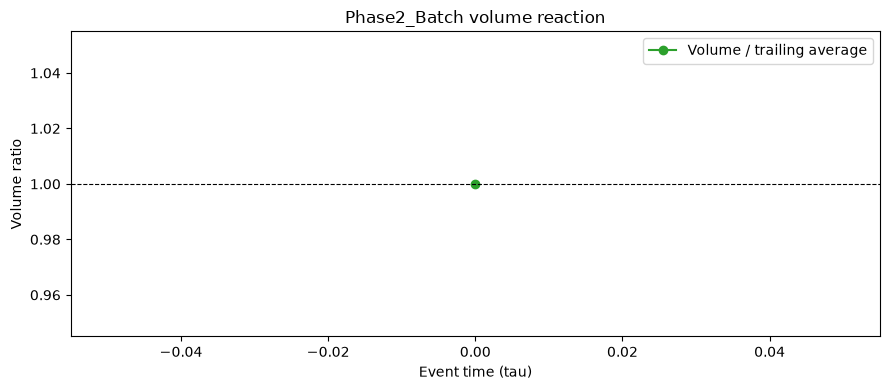

In [3]:
from src.pipeline.run_batch import run_phase2_batch

DEMO_OUTPUT.mkdir(parents=True, exist_ok=True)
runtime_config = yaml.safe_load(SOURCE_CONFIG.read_text(encoding="utf-8"))
runtime_config["output_dir"] = DEMO_OUTPUT.relative_to(ROOT).as_posix()
runtime_config["cache_dir"] = DEMO_CACHE.relative_to(ROOT).as_posix()
runtime_config_path = DEMO_OUTPUT / "notebook_runtime_config.yaml"
runtime_config_path.write_text(yaml.safe_dump(runtime_config, sort_keys=False), encoding="utf-8")

logging.getLogger().handlers.clear()
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    run_phase2_batch(runtime_config_path, force=True)

print("✓ Pipeline completed — 1 illustrative issuer, 4 candidates, local fixtures only")

<!-- Presenter notes (1:05–1:32): This is the core output. Trace one row left to right: stable event key, filing provenance, high extraction confidence and attachment score, then a human review outcome and whether it is allowed into research. -->
## 4. Structured evidence packet

Each candidate keeps a stable identity, filing provenance, evidence-quality fields, and its review decision. The engine separates extraction confidence from the independent question of whether the candidate is eligible for validated research.

In [4]:
queue = pd.read_csv(DEMO_OUTPUT / "candidate_review_queue.csv")
packet = pd.DataFrame({
    "Event key": queue["event_review_id"],
    "Candidate": queue["candidate_event_date"],
    "Filing provenance": queue["canonical_filing_type"] + " · " + queue["canonical_filing_date"],
    "Source": queue["source_kind"],
    "Confidence": queue["confidence"],
    "Attachment": queue["attachment_score"],
    "Review decision": queue["review_status"],
    "Effective date": queue["effective_event_date"],
    "Validated": queue["included_in_event_study"].map({True: "Yes", False: "No"}),
})
display(
    packet.style
    .hide(axis="index")
    .format({"Confidence": "{:.2f}", "Attachment": "{:.2f}"})
    .set_properties(subset=["Event key"], **{"font-size": "0.82em"})
    .set_table_styles([{"selector": "th", "props": [("background-color", "#102a43"), ("color", "white")]}])
)

Event key,Candidate,Filing provenance,Source,Confidence,Attachment,Review decision,Effective date,Validated
TST|specific_purchase|2024-03-29,2024-03-29,10-K · 2024-02-15,fixture,0.95,0.85,accepted,2024-03-29,Yes
TST|specific_purchase|2024-06-28,2024-06-28,DEF 14A · 2024-04-15,fixture,0.95,0.85,corrected,2024-06-27,Yes
TST|specific_purchase|2024-09-30,2024-09-30,10-K · 2024-08-01,fixture,0.95,0.85,rejected,2024-09-30,No
TST|specific_purchase|2024-12-31,2024-12-31,DEF 14A · 2024-10-15,fixture,0.95,0.85,unreviewed,2024-12-31,No


<!-- Presenter notes (1:32–1:58): Point to the bar chart: four candidates, but only accepted and corrected entries pass. The corrected date demonstrates a reviewer can improve a candidate; rejected and unreviewed rows remain auditable but cannot silently leak into event windows. -->
## 5. Validation and research discipline

The actual fixture deliberately demonstrates four states: accepted, corrected, rejected, and unreviewed. Only the accepted and corrected records generate validated event-study observations.

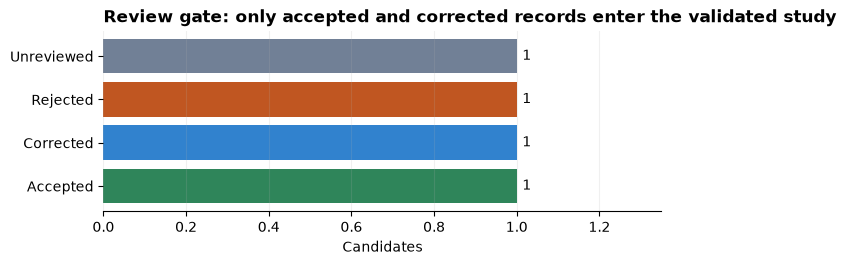

Ticker,Validated event,Confidence,Raw return,Benchmark return,Abnormal return,Volume ratio
TST,2024-03-29,0.95,+1.00%,+0.25%,+0.75%,1.00
TST,2024-06-27,0.95,+0.99%,+0.25%,+0.74%,1.00


✓ Assertions passed: review-gated output is deterministic and internally consistent.


In [5]:
audit = pd.read_csv(DEMO_OUTPUT / "espp_date_audit.csv")
windows = pd.read_csv(DEMO_OUTPUT / "all_event_windows.csv")
status = pd.read_csv(DEMO_OUTPUT / "company_processing_status.csv")

assert queue["review_status"].value_counts().to_dict() == {"accepted": 1, "corrected": 1, "rejected": 1, "unreviewed": 1}
assert set(windows["event_date"]) == {"2024-03-29", "2024-06-27"}
assert audit.loc[audit["included_in_event_study"], "review_status"].isin(["accepted", "corrected"]).all()

counts = queue["review_status"].value_counts().reindex(["accepted", "corrected", "rejected", "unreviewed"])
colors = ["#2f855a", "#3182ce", "#c05621", "#718096"]
fig, ax = plt.subplots(figsize=(7.2, 2.35))
bars = ax.barh(counts.index.str.title(), counts.values, color=colors)
ax.bar_label(bars, padding=4)
ax.set_xlim(0, 1.35)
ax.set_xlabel("Candidates")
ax.set_title("Review gate: only accepted and corrected records enter the validated study", loc="left", weight="bold")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.18)
plt.show()

window_view = windows.loc[windows["tau"] == 0, ["ticker", "event_date", "confidence", "raw_ret", "benchmark_ret", "abnormal_ret", "vol_ratio"]].copy()
window_view.columns = ["Ticker", "Validated event", "Confidence", "Raw return", "Benchmark return", "Abnormal return", "Volume ratio"]
display(
    window_view.style.hide(axis="index").format({
        "Confidence": "{:.2f}", "Raw return": "{:+.2%}", "Benchmark return": "{:+.2%}",
        "Abnormal return": "{:+.2%}", "Volume ratio": "{:.2f}",
    }).set_table_styles([{"selector": "th", "props": [("background-color", "#102a43"), ("color", "white")]}])
)
print("✓ Assertions passed: review-gated output is deterministic and internally consistent.")

<!-- Presenter notes (1:58–2:18): Position the artifacts as an evidence family for a larger research stack. Be explicit: the repository has no broker, portfolio, or decision engine; a downstream system must combine it with other evidence and controls. -->
## 6. Where this fits downstream

The repository is an auditable research-data layer. It can provide one evidence family to a downstream research-opportunity or finance-decision system, but it does not independently produce a complete investment decision.

| Artifact contract | What it carries | Downstream use |
| --- | --- | --- |
| `candidate_review_queue.csv` | Raw-to-canonical candidate provenance and quality | Research triage / human review |
| `espp_date_audit.csv` | Review state and effective event date | Validated-event join key |
| `all_event_windows.csv` | Daily raw, benchmark, and abnormal-return observations | Event-study reporting / independent model inputs |

No broker, portfolio optimizer, position-sizing logic, or live-trading workflow is implemented here.

<!-- Presenter notes (2:18–2:35): Deliver the three takeaways briskly, then end on the final sentence. Leave this frame on screen for a beat. -->
## 7. What this demonstration established

1. **Evidence first:** ESPP filing references become traceable candidate records, not hidden signals.
2. **Review-gated research:** confidence and provenance remain visible; rejected or unreviewed candidates stay out of validated windows.
3. **Reusable outputs:** structured artifacts can feed broader research while preserving the boundary between evidence, research, and investment decisions.

> **Employee Flow Event Engine turns ambiguous filing text into disciplined, reproducible research evidence.**